<a href="https://colab.research.google.com/github/MiguelAP6/IAAC/blob/Pedro-Ferreira/Model_Evaluation_PF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset não encontrado. Por favor, faz o upload do ficheiro CSV:


Saving archive.zip to archive.zip
A treinar classificadores base para avaliação...

=== PARTE 4: AVALIAÇÃO E DIAGNÓSTICO DE OVERFITTING (M) ===



,Modelo,F1 (Treino),F1 (Teste),Diferença (Gap),Diagnóstico
7,Gradient Boosting (Boosting),0.597716,0.224612,0.373104,Overfitting
5,Random Forest (Bagging),1.000000,0.196363,0.803637,Overfitting
3,Naïve Bayes (Gaussian),0.216699,0.190919,0.025779,Underfitting
4,Support Vector Machine (SVM),0.347525,0.187725,0.159800,Overfitting
1,K-Nearest Neighbors (KNN),0.428723,0.186199,0.242524,Overfitting
8,XGBoost (Boosting),0.997915,0.183055,0.814861,Overfitting
2,Árvore de Decisão,1.000000,0.182494,0.817506,Overfitting
0,Regressão Logística,0.204285,0.180421,0.023864,Underfitting
6,AdaBoost (Boosting),0.206004,0.147154,0.058850,Underfitting


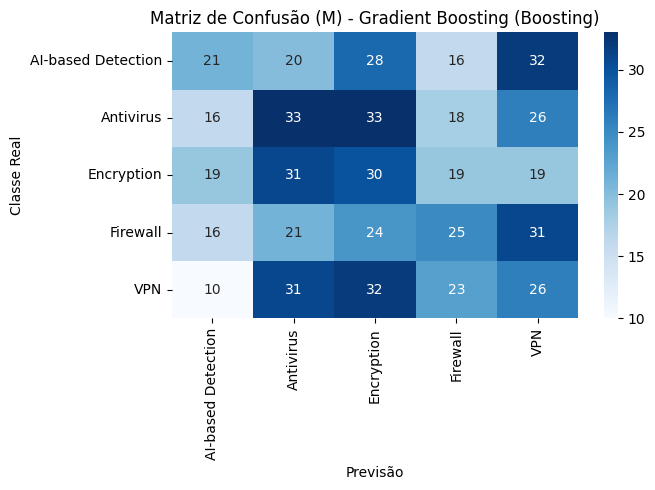


=== CURVAS AUC-ROC MULTICLASSE (M) ===


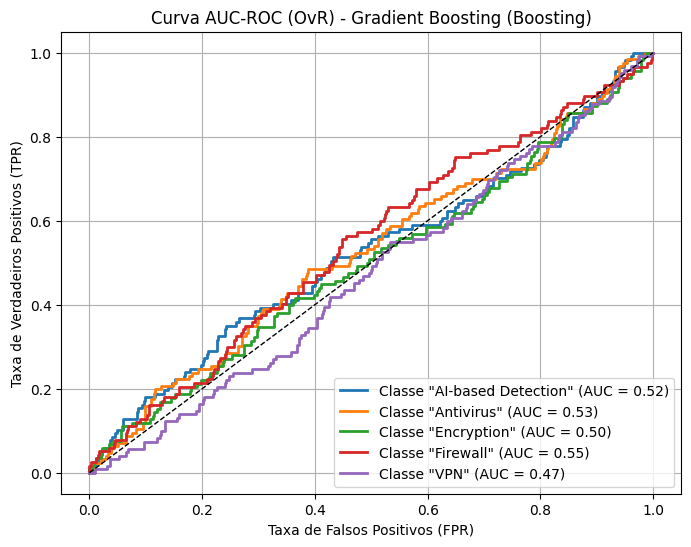


=== AFINAÇÃO DE HIPERPARÂMETROS (GRIDSEARCHCV - M) ===
Melhores Hiperparâmetros: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Melhor F1 em 5-Fold Cross Validation: 0.1914
F1-Score Final em Teste (Modelo Otimizado): 0.1990


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score,
    precision_score, recall_score, roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Garantir existência da pasta 'src' e do módulo 'data_processing.py' (M)
if not os.path.exists("src/data_processing.py"):
    os.makedirs("src", exist_ok=True)
    code_src = """import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

def load_and_clean_data(df_input, target_col='Threat Level'):
    df = df_input.dropna().copy()
    id_cols = [c for c in df.columns if 'id' in c.lower() or 'date' in c.lower() or 'timestamp' in c.lower()]
    if id_cols:
        df = df.drop(columns=id_cols)
    return df

def prepare_pipeline(df, target_col='Threat Level'):
    if target_col not in df.columns:
        target_col = df.columns[-1]

    X = df.drop(columns=[target_col])
    y = df[target_col]

    label_encoders = {}
    for col in X.select_dtypes(include=['object', 'category']).columns:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        label_encoders[col] = le

    target_encoder = LabelEncoder()
    y_encoded = target_encoder.fit_transform(y.astype(str))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    return {
        'X_train_scaled': X_train_scaled,
        'X_test_scaled': X_test_scaled,
        'y_train': y_train,
        'y_test': y_test,
        'scaler': scaler,
        'target_encoder': target_encoder,
        'label_encoders': label_encoders,
        'feature_names': list(X.columns)
    }
"""
    with open("src/data_processing.py", "w") as f:
        f.write(code_src)

# 2. Carregar/Preparar Dados se não estiverem em memória (M)
if 'X_train_scaled' not in globals() or 'target_encoder' not in globals():
    from src.data_processing import load_and_clean_data, prepare_pipeline

    if 'df' not in globals():
        print("Dataset não encontrado. Por favor, faz o upload do ficheiro CSV:")
        uploaded = files.upload()
        file_name = list(uploaded.keys())[0]
        df = pd.read_csv(file_name)

    df_clean = load_and_clean_data(df)
    prep_data = prepare_pipeline(df_clean)

    X_train_scaled = prep_data['X_train_scaled']
    X_test_scaled = prep_data['X_test_scaled']
    y_train = prep_data['y_train']
    y_test = prep_data['y_test']
    scaler = prep_data['scaler']
    target_encoder = prep_data['target_encoder']
    label_encoders = prep_data['label_encoders']
    feature_names = prep_data['feature_names']

# 3. Inicializar e Treinar Classificadores caso 'classifiers' não exista (M)
if 'classifiers' not in globals():
    from sklearn.linear_model import LogisticRegression
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.naive_bayes import GaussianNB
    from sklearn.svm import SVC
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier

    try:
        from xgboost import XGBClassifier
        has_xgb = True
    except ImportError:
        has_xgb = False

    classifiers = {
        "Regressão Logística": LogisticRegression(max_iter=1000, random_state=42),
        "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
        "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
        "Naïve Bayes (Gaussian)": GaussianNB(),
        "Support Vector Machine (SVM)": SVC(kernel='rbf', random_state=42, probability=True),
        "Random Forest (Bagging)": RandomForestClassifier(n_estimators=100, random_state=42),
        "AdaBoost (Boosting)": AdaBoostClassifier(random_state=42),
        "Gradient Boosting (Boosting)": GradientBoostingClassifier(random_state=42)
    }

    if has_xgb:
        classifiers["XGBoost (Boosting)"] = XGBClassifier(random_state=42, eval_metric='logloss')

    print("A treinar classificadores base para avaliação...")
    for name, model in classifiers.items():
        model.fit(X_train_scaled, y_train)

# 4. PARTE 4: Avaliação e Diagnóstico de Overfitting / Underfitting (M)
print("\n=== PARTE 4: AVALIAÇÃO E DIAGNÓSTICO DE OVERFITTING (M) ===\n")

diag_list = []
for name, model in classifiers.items():
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    f1_tr = f1_score(y_train, y_train_pred, average='weighted', zero_division=0)
    f1_te = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
    gap = f1_tr - f1_te

    if gap > 0.10:
        status = "Overfitting"
    elif f1_tr < 0.60 and f1_te < 0.60:
        status = "Underfitting"
    else:
        status = "Good Fit (Equilibrado)"

    diag_list.append({
        "Modelo": name,
        "F1 (Treino)": f1_tr,
        "F1 (Teste)": f1_te,
        "Diferença (Gap)": gap,
        "Diagnóstico": status
    })

df_diag = pd.DataFrame(diag_list).sort_values(by="F1 (Teste)", ascending=False)
display(df_diag)

# Matriz de Confusão do Melhor Modelo Base (M)
best_base_name = df_diag.iloc[0]["Modelo"]
best_base_model = classifiers[best_base_name]
y_best_pred = best_base_model.predict(X_test_scaled)

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_)
plt.title(f'Matriz de Confusão (M) - {best_base_name}')
plt.xlabel('Previsão')
plt.ylabel('Classe Real')
plt.tight_layout()
plt.show()

# Curvas AUC-ROC Multiclasse (M)
print("\n=== CURVAS AUC-ROC MULTICLASSE (M) ===")
classes_list = np.unique(y_test)
n_classes = len(classes_list)
y_test_bin = label_binarize(y_test, classes=classes_list)

if hasattr(best_base_model, "predict_proba"):
    y_score = best_base_model.predict_proba(X_test_scaled)
    plt.figure(figsize=(8, 6))

    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'Classe "{target_encoder.classes_[i]}" (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=1)
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title(f'Curva AUC-ROC (OvR) - {best_base_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

# Otimização de Hiperparâmetros via GridSearchCV (M)
print("\n=== AFINAÇÃO DE HIPERPARÂMETROS (GRIDSEARCHCV - M) ===")
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', None]
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

best_tuned_model = grid.best_estimator_
print(f"Melhores Hiperparâmetros: {grid.best_params_}")
print(f"Melhor F1 em 5-Fold Cross Validation: {grid.best_score_:.4f}")

y_tuned_pred = best_tuned_model.predict(X_test_scaled)
print(f"F1-Score Final em Teste (Modelo Otimizado): {f1_score(y_test, y_tuned_pred, average='weighted'):.4f}")